In [1]:
!pip -q install ultralytics

In [ ]:
import os, math, random, time, gc, json, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import NearestNeighbors
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
    classification_report, matthews_corrcoef, roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score, log_loss
)
warnings.filterwarnings("ignore")

# ======================= CONFIG - change these =======================
QUICK_MODE = False      # True = small demo run (minutes). False = full run.
RUN_ADSOA  = True  
USE_AMP    = True       # mixed precision on GPU: faster and uses less memory
SEED       = 42
IMG_SIZE   = 224
BATCH_SIZE = 16
YOLO_WEIGHTS = "yolov8n-cls.pt"
OUT_DIR    = "/kaggle/working"

if QUICK_MODE:
    N_SAMPLES = 1600    # use only this many training memes
    EPOCHS, PATIENCE = 2, 2
    N_FOLDS, MAX_FOLDS = 5, 2
else:
    N_SAMPLES = None    # use everything
    EPOCHS, PATIENCE = 8, 3     # earlier runs peaked at epoch ~5, so 8 is enough
    N_FOLDS, MAX_FOLDS = 5, 5   # set MAX_FOLDS = 2 to run only 2 of the 5 folds and save time
# =====================================================================
assert N_SAMPLES is None or N_SAMPLES >= 800, \
    "N_SAMPLES must be at least 800: the 512-d TF-IDF/SVD text features need >= 512 training samples in every fold."

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU found. Session options -> Accelerator -> choose a GPU, then restart.")
print(f"QUICK_MODE={QUICK_MODE}  EPOCHS={EPOCHS}  PATIENCE={PATIENCE}  N_FOLDS={N_FOLDS}  MAX_FOLDS={MAX_FOLDS}")

Device: cuda
GPU: Tesla T4
QUICK_MODE=False  EPOCHS=8  PATIENCE=3  N_FOLDS=5  MAX_FOLDS=5


## 1. Load data 

In [3]:
def find_dataset_root(input_root="/kaggle/input"):
    for root, dirs, files in os.walk(input_root):
        if "train.jsonl" in files:
            return root
    return None

dataset_path = find_dataset_root()
if dataset_path is None:
    print("Could not find train.jsonl. What is under /kaggle/input:")
    for r, d, f in os.walk("/kaggle/input"):
        print(r, "| folders:", d[:6], "| files:", f[:6])
        if r.count(os.sep) > 5:
            break
    raise FileNotFoundError("train.jsonl not found. Did you use 'Add Input' to add the Facebook Hateful Meme Dataset?")

print("Dataset root:", dataset_path)
print("Contents    :", os.listdir(dataset_path))
assert os.path.isdir(os.path.join(dataset_path, "img")), "img/ folder not found next to train.jsonl"

train_df = pd.read_json(os.path.join(dataset_path, "train.jsonl"), lines=True)
print("Training samples:", len(train_df), "| columns:", train_df.columns.tolist())

test_path = os.path.join(dataset_path, "test.jsonl")
test_df = pd.read_json(test_path, lines=True) if os.path.exists(test_path) else None
print("Test samples:", None if test_df is None else len(test_df))
print(train_df["label"].value_counts())
print(train_df.isnull().sum())

Dataset root: /kaggle/input/datasets/parthplc/facebook-hateful-meme-dataset/data
Contents    : ['LICENSE.txt', 'README.md', 'dev.jsonl', 'img', 'test.jsonl', 'train.jsonl']
Training samples: 8500 | columns: ['id', 'img', 'label', 'text']
Test samples: 1000
label
0    5450
1    3050
Name: count, dtype: int64
id       0
img      0
label    0
text     0
dtype: int64


## 2. Cleaning, de-duplicate BEFORE splitting, drop missing images

In [4]:
print("Duplicate rows:", train_df.duplicated().sum())
print("Duplicate text values:", train_df["text"].duplicated().sum())
train_df = train_df.drop_duplicates(subset=["text"]).reset_index(drop=True)
print("Training samples after de-duplication:", len(train_df))

from pathlib import Path

img_root = Path(dataset_path)

missing_train = [
    p for p in train_df["img"]
    if not (img_root / p).is_file()
]
print("Missing training images:", len(missing_train))

train_df = train_df[
    ~train_df["img"].isin(missing_train)
].reset_index(drop=True)

if test_df is not None:
    missing_test = [
        p for p in test_df["img"]
        if not (img_root / p).is_file()
    ]
    print("Missing testing images:", len(missing_test))

    test_df = test_df[
        ~test_df["img"].isin(missing_test)
    ].reset_index(drop=True)

if N_SAMPLES is not None and len(train_df) > N_SAMPLES:
    train_df, _ = train_test_split(train_df, train_size=N_SAMPLES, random_state=SEED, stratify=train_df["label"])
    train_df = train_df.reset_index(drop=True)
    print("QUICK_MODE: using", len(train_df), "training memes")

train_data, val_data = train_test_split(
    train_df, test_size=0.2, random_state=42, stratify=train_df["label"]
)
train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)
train_data["clean_text"] = train_data["text"].astype(str)
val_data["clean_text"] = val_data["text"].astype(str)

print("Train:", len(train_data), "| Val:", len(val_data))
print(train_data["label"].value_counts().to_dict(), val_data["label"].value_counts().to_dict())

Duplicate rows: 0
Duplicate text values: 1428
Training samples after de-duplication: 7072
Missing training images: 0
Missing testing images: 0
Train: 5657 | Val: 1415
{0: 3765, 1: 1892} {0: 942, 1: 473}


In [5]:
print("Original rows:", len(train_df))
print("Unique texts:", train_df["text"].nunique())
print("Duplicate texts:", train_df["text"].duplicated().sum())

Original rows: 7072
Unique texts: 7072
Duplicate texts: 0


In [6]:
missing_train = [p for p in train_df["img"]
                 if not os.path.exists(os.path.join(dataset_path, p))]

## 3. Cache all images in RAM 

In [5]:
def load_resized(rel_path):
    try:
        im = Image.open(os.path.join(dataset_path, rel_path)).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        return np.array(im, dtype=np.uint8)
    except Exception:
        return np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)

all_paths = sorted(set(train_df["img"].tolist()))
t0 = time.time()
with ThreadPoolExecutor(max_workers=4) as ex:
    arrays = list(tqdm(ex.map(load_resized, all_paths), total=len(all_paths), desc="Caching images"))
IMG_CACHE = dict(zip(all_paths, arrays))
print(f"Cached {len(IMG_CACHE)} images in {time.time()-t0:.0f}s  (~{sum(a.nbytes for a in arrays)/1e9:.2f} GB)")

Caching images:   0%|          | 0/7072 [00:00<?, ?it/s]

Cached 7072 images in 281s  (~1.06 GB)


## 4. TF-IDF 512-d text features

In [6]:
TEXT_EMB_DIM = 512

tfidf = TfidfVectorizer(max_features=20000, stop_words="english")
tfidf.fit(train_data["clean_text"].tolist())        # fit ONLY on training text (no leakage)

X_train_tfidf_sparse = tfidf.transform(train_data["clean_text"].tolist())
X_val_tfidf_sparse = tfidf.transform(val_data["clean_text"].tolist())

svd = TruncatedSVD(n_components=TEXT_EMB_DIM, random_state=SEED)
X_train_text_array = svd.fit_transform(X_train_tfidf_sparse).astype(np.float32)
X_val_text_array = svd.transform(X_val_tfidf_sparse).astype(np.float32)

y_train = train_data["label"].values
y_val = val_data["label"].values
print("Training text features:", X_train_text_array.shape)
print("Validation text features:", X_val_text_array.shape)

Training text features: (5657, 512)
Validation text features: (1415, 512)


## 5. Class weights - minority class

In [ ]:
minority_class = 1
minority_indices = np.where(y_train == minority_class)[0]
X_minority = X_train_text_array[minority_indices]

k = 5
nn_model = NearestNeighbors(n_neighbors=k + 1, metric="euclidean")
nn_model.fit(X_minority)
distances, neighbor_indices = nn_model.kneighbors(X_minority)

n_class_0 = np.sum(y_train == 0)
n_class_1 = np.sum(y_train == 1)
n_synthetic = max(0, n_class_0 - n_class_1)
print("Synthetic samples required:", n_synthetic)

rng = np.random.RandomState(SEED)
synthetic_samples, synthetic_source_row = [], []
for _ in range(n_synthetic):
    i = rng.randint(0, len(X_minority))
    neighbor_position = rng.randint(1, neighbor_indices.shape[1])
    j = neighbor_indices[i][neighbor_position]
    x_i, x_j = X_minority[i], X_minority[j]
    lam = rng.rand()
    x_new = x_i + lam * (x_j - x_i)                 # Eq. (1)
    synthetic_samples.append(x_new)
    synthetic_source_row.append(minority_indices[i])

synthetic_samples = np.array(synthetic_samples, dtype=np.float32)
synthetic_source_row = np.array(synthetic_source_row, dtype=np.int64)

if n_synthetic > 0:
    X_train_text_balanced = np.vstack([X_train_text_array, synthetic_samples]).astype(np.float32)
    y_train_balanced = np.concatenate([y_train, np.full(len(synthetic_samples), minority_class)])
else:
    X_train_text_balanced, y_train_balanced = X_train_text_array, y_train

train_img_paths = np.array(train_data["img"].tolist() + [train_data["img"].iloc[r] for r in synthetic_source_row])

class_weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight_dict = {int(c): w for c, w in zip(np.unique(y_train), class_weights)}
print("X_train_text_balanced:", X_train_text_balanced.shape, "| class weights:", class_weight_dict)

In [7]:

# Calculate class weights using the original training labels
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = {
    int(c): float(w)
    for c, w in zip(np.unique(y_train), class_weights)
}

print("Class weights:", class_weight_dict)

# Use the original training data — no SMOTE
train_img_paths = train_data["img"].tolist()

X_train_text_balanced = X_train_text_array
y_train_balanced = y_train


Class weights: {0: 0.751261620185923, 1: 1.4949788583509513}


In [8]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class MemeDataset(Dataset):
    def __init__(self, img_paths, text_embeddings, labels, cache):
        self.img_paths = list(img_paths)
        self.text_embeddings = np.asarray(text_embeddings, dtype=np.float32)
        self.labels = np.asarray(labels, dtype=np.int64)
        self.cache = cache

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        arr = self.cache[self.img_paths[idx]]
        image = torch.from_numpy(arr).permute(2, 0, 1).float().div_(255.0)
        image = (image - MEAN) / STD
        text_emb = torch.from_numpy(self.text_embeddings[idx])
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, text_emb, label

train_ds = MemeDataset(train_img_paths, X_train_text_balanced, y_train_balanced, IMG_CACHE)
val_ds = MemeDataset(val_data["img"].tolist(), X_val_text_array, y_val, IMG_CACHE)
print("Train dataset size:", len(train_ds), "| Val dataset size:", len(val_ds))

Train dataset size: 5657 | Val dataset size: 1415


## 7. Model: YOLOv8 backbone + neck → LPFP → concat text → MLP 

In [9]:
from ultralytics import YOLO

class YOLOv8BackboneNeck(nn.Module):
    """YOLOv8 backbone/neck with the classification head removed (Table 2 / Table 6)."""
    def __init__(self, weights=None, projected_channels=1280):
        super().__init__()
        yolo = YOLO(weights or YOLO_WEIGHTS)
        self.backbone = yolo.model.model[:-1]
        for p in self.backbone.parameters():
            p.requires_grad = True
        with torch.no_grad():
            dummy = torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)
            feat = self._forward_backbone(dummy)
            in_ch = feat.shape[1]
        self.feat_channels = in_ch
        self.projected_channels = projected_channels
        self.proj_conv = nn.Conv2d(in_ch, projected_channels, kernel_size=1)

    def _forward_backbone(self, x):
        for layer in self.backbone:
            x = layer(x)
        return x

    def forward(self, x):
        return self.proj_conv(self._forward_backbone(x))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [13]:
class DilatedConv(nn.Module):
    """Eq. (3): Sc = sigma(w*A + b) -- a dilated convolution + activation."""
    def __init__(self, in_ch, out_ch, kernel_size=3, dilation=1):
        super().__init__()
        pad = dilation * (kernel_size - 1) // 2
        self.conv = nn.Conv2d(in_ch, out_ch, kernel_size, padding=pad, dilation=dilation)
        self.act = nn.SiLU()
    def forward(self, x):
        return self.act(self.conv(x))


class DepthwiseSeparableConv(nn.Module):
    def __init__(self, channels, kernel_size=3, dilation=1):
        super().__init__()
        pad = dilation * (kernel_size - 1) // 2
        self.depthwise = nn.Conv2d(channels, channels, kernel_size, padding=pad,
                                   dilation=dilation, groups=channels)
        self.bn = nn.BatchNorm2d(channels)
        self.act = nn.SiLU()
    def forward(self, x):
        return self.act(self.bn(self.depthwise(x)))


class PointwiseConv(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.pointwise = nn.Conv2d(channels, channels, kernel_size=1)
        self.bn = nn.BatchNorm2d(channels)
        self.act = nn.SiLU()
    def forward(self, x):
        return self.act(self.bn(self.pointwise(x)))


class RecursiveBlock(nn.Module):
    """Eq. (6)-(9): 2 depthwise-separable convs -> 1 pointwise conv -> residual add."""
    def __init__(self, channels):
        super().__init__()
        self.dw1 = DepthwiseSeparableConv(channels)
        self.dw2 = DepthwiseSeparableConv(channels)
        self.pw = PointwiseConv(channels)
    def forward(self, fe_n0, fe_n1):
        fe_t1 = self.dw1(fe_n1)      # Eq. (6)
        fe_t2 = self.dw2(fe_t1)      # Eq. (7)
        fe_t3 = self.pw(fe_t2)       # Eq. (8)
        return fe_t3 + fe_n0         # Eq. (9)


class FeatureEnhancementBlock(nn.Module):
    """Eq. (10)-(12): 3 dilated convs + BN + ReLU, conv, then D = tanh(concat(M, Y))."""
    def __init__(self, channels):
        super().__init__()
        self.dilated_convs = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=2, dilation=2), nn.BatchNorm2d(channels),
            nn.Conv2d(channels, channels, 3, padding=4, dilation=4), nn.BatchNorm2d(channels),
            nn.Conv2d(channels, channels, 3, padding=8, dilation=8), nn.BatchNorm2d(channels),
        )
        self.act = nn.ReLU()
        self.out_conv = nn.Conv2d(channels, channels, kernel_size=1)
    def forward(self, fe_t_n, y):
        eb_n = self.act(self.dilated_convs(fe_t_n))   # Eq. (10)
        m = self.out_conv(eb_n)                        # Eq. (11)
        return torch.tanh(torch.cat([m, y], dim=1))    # Eq. (12)


class DualAttentionBlock(nn.Module):
    """Eq. (13): Fe_DAB = spatial_attention(D) * channel_attention(D)."""
    def __init__(self, channels):
        super().__init__()
        reduced = channels // 2
        self.reduce = nn.Conv2d(channels, reduced, kernel_size=1)
        bottleneck = max(reduced // 8, 1)
        self.channel_fc1 = nn.Linear(reduced, bottleneck)
        self.channel_fc2 = nn.Linear(bottleneck, reduced)
        self.spatial_conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
    def forward(self, d):
        d = self.reduce(d)
        avg_pool = d.mean(dim=[2, 3])
        ca = torch.sigmoid(self.channel_fc2(F.relu(self.channel_fc1(avg_pool))))
        ca = ca.unsqueeze(-1).unsqueeze(-1)
        avg_map = d.mean(dim=1, keepdim=True)
        max_map, _ = d.max(dim=1, keepdim=True)
        sa = torch.sigmoid(self.spatial_conv(torch.cat([avg_map, max_map], dim=1)))
        return d * ca * sa


class LPFP(nn.Module):
    """Lightweight Pyramid Feed Perceptron, Eq. (2)-(13); 5 Laplacian pyramid levels."""
    def __init__(self, in_channels, n_levels=5, out_dim=768):
        super().__init__()
        self.n_levels = n_levels
        self.shallow = DilatedConv(in_channels, in_channels, dilation=1)
        self.dc1 = DilatedConv(in_channels, in_channels, dilation=1)
        self.dc2 = DilatedConv(in_channels, in_channels, dilation=2)
        self.recursive1 = RecursiveBlock(in_channels)
        self.recursive2 = RecursiveBlock(in_channels)
        self.feb = FeatureEnhancementBlock(in_channels)
        self.dab = DualAttentionBlock(in_channels * 2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(in_channels, out_dim)

    def _laplacian_pyramid(self, x):
        """Eq. (2): L_n(A) = G_n(A) - upsample(G_{n+1}(A))."""
        levels = [x]
        cur = x
        for _ in range(self.n_levels - 1):
            down = F.avg_pool2d(cur, 2) if min(cur.shape[2], cur.shape[3]) > 1 else cur
            up = F.interpolate(down, size=cur.shape[2:], mode="bilinear", align_corners=False)
            levels.append(cur - up)
            cur = down
        return levels

    def forward(self, feat_map):
        pyramid = self._laplacian_pyramid(feat_map)
        target_size = feat_map.shape[2:]
        pyramid_resized = [
            level if level.shape[2:] == target_size else
            F.interpolate(level, size=target_size, mode="bilinear", align_corners=False)
            for level in pyramid
        ]
        multi_scale = torch.stack(pyramid_resized, dim=0).mean(dim=0)

        shallow = self.shallow(multi_scale)          # Eq. (3)
        fe_n0 = self.dc1(shallow)                    # Eq. (4)
        fe_n1 = self.dc2(fe_n0)                      # Eq. (5)
        fe = self.recursive1(fe_n0, fe_n1)           # Eq. (6)-(9), block 1
        fe = self.recursive2(fe_n0, fe)              # Eq. (6)-(9), block 2
        d = self.feb(fe, fe_n0)                      # Eq. (10)-(12)
        fe_dab = self.dab(d)                         # Eq. (13)
        pooled = self.pool(fe_dab).flatten(1)
        return self.fc(pooled)


class MLP(nn.Module):
    """MLP classifier, Table 6 defaults: hidden_dim=512, expansion=2, dropout=0.3."""
    def __init__(self, in_dim=1280, hidden_dim=512, expansion=2, dropout=0.3, n_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim * expansion), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim * expansion, n_classes),
        )
    def forward(self, x):
        return self.net(x)


class ILwYOLOv8Net(nn.Module):
    def __init__(self, text_dim=512, visual_dim=768, hidden_dim=512, expansion=2, dropout=0.3):
        super().__init__()
        self.backbone = YOLOv8BackboneNeck(projected_channels=1280)
        self.lpfp = LPFP(in_channels=self.backbone.projected_channels, out_dim=visual_dim)
        self.mlp = MLP(in_dim=visual_dim + text_dim, hidden_dim=hidden_dim,
                       expansion=expansion, dropout=dropout)

    def forward(self, images, text_emb):
        feat_map = self.backbone(images)
        visual_feat = self.lpfp(feat_map)
        return self.mlp(torch.cat([visual_feat, text_emb], dim=1))

## 8. Training / evaluation helpers

In [14]:
def make_scaler():
    enabled = USE_AMP and DEVICE.type == "cuda"
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)

def autocast_ctx():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                          enabled=(USE_AMP and DEVICE.type == "cuda"))

def make_loader(ds, shuffle):
    # images are already in RAM, so num_workers=0 is fastest and avoids worker-shutdown warnings
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0,
                      pin_memory=(DEVICE.type == "cuda"))

def make_optimizer(model, lr):
    backbone_params = list(model.backbone.parameters())
    head_params = list(model.lpfp.parameters()) + list(model.mlp.parameters())
    return torch.optim.Adam([
        {"params": backbone_params, "lr": lr * 0.1},
        {"params": head_params, "lr": lr},
    ], weight_decay=1e-4)

def train_one_epoch(model, loader, optimizer, criterion, scaler=None):
    model.train()
    total_loss, total_samples = 0.0, 0
    progress = tqdm(loader, desc="train", leave=False)
    for images, text_features, labels in progress:
        images = images.to(DEVICE, non_blocking=True)
        text_features = text_features.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, dtype=torch.long, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with autocast_ctx():
            outputs = model(images, text_features)
        loss = criterion(outputs.float(), labels)

        if scaler is not None and scaler.is_enabled():
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        n = labels.size(0)
        total_loss += loss.item() * n
        total_samples += n
        progress.set_postfix(loss=f"{loss.item():.4f}")
    return total_loss / max(total_samples, 1)


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_probs, all_preds, all_labels = [], [], []
    for images, text_emb, labels in loader:
        images, text_emb, labels = images.to(DEVICE), text_emb.to(DEVICE), labels.to(DEVICE)
        with autocast_ctx():
            logits = model(images, text_emb)
        logits = logits.float()
        loss = criterion(logits, labels)
        total_loss += loss.item() * images.size(0)
        probs = F.softmax(logits, dim=1)[:, 1]
        all_probs.extend(probs.cpu().numpy())
        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    return (total_loss / len(loader.dataset), np.array(all_labels),
            np.array(all_preds), np.array(all_probs))


def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 9. AdSOA hyper-parameter search 

In [15]:
HP_SEARCH_SPACE = {"lr": (1e-5, 1e-3), "dropout": (0.2, 0.5), "hidden_dim": (64, 512)}
HP_NAMES = list(HP_SEARCH_SPACE.keys())
LB = np.array([HP_SEARCH_SPACE[k][0] for k in HP_NAMES])
UB = np.array([HP_SEARCH_SPACE[k][1] for k in HP_NAMES])
DIM = len(HP_NAMES)

def decode_solution(vec):
    lr = float(vec[0])
    dropout = float(np.clip(vec[1], 0.1, 0.6))
    hidden_dim = int(np.clip(round(vec[2] / 32) * 32, 32, 512))
    return {"lr": lr, "dropout": dropout, "hidden_dim": hidden_dim}


class AdSOA:
    """Table 6 AdSOA defaults: Alpha=0.8-0.9, Beta=0.2-0.3, success_window=10-15, k_init=1.0, Eps=1e-8."""
    def __init__(self, fitness_fn, pop_size=6, max_iter=4, z1=0.6,
                 alpha=0.85, beta=0.25, success_window=12, k_init=1.0, eps=1e-8, seed=SEED):
        self.fitness_fn = fitness_fn
        self.pop_size = pop_size
        self.max_iter = max_iter
        self.z1, self.alpha, self.beta = z1, alpha, beta
        self.success_window, self.k_init, self.eps = success_window, k_init, eps
        self.rng = np.random.RandomState(seed)
        self.population = self.rng.uniform(LB, UB, size=(pop_size, DIM))
        self.fitness = np.full(pop_size, np.inf)

    def _clip(self, v):
        return np.clip(v, LB, UB)

    def _gto_explore(self, it):
        """Eq. (17)-(21)."""
        c4 = math.cos(2 * self.rng.uniform()) + 1
        c1 = c4 * (1 - it / self.max_iter)
        c5 = self.rng.uniform(-1, 1)
        c2 = c1 * c5
        c6 = self.rng.uniform(-c1, c1)
        best_idx = int(np.argmin(self.fitness)) if np.isfinite(self.fitness).any() else 0
        GS = self.population[best_idx]
        new_pop = np.empty_like(self.population)
        for i in range(self.pop_size):
            r = self.rng.uniform()
            GA = self.population[i]
            c3 = c6 * GA
            if r < self.z1:
                new_sol = LB + self.rng.uniform() * (UB - LB)
            elif r >= 0.5:
                ra2 = self.rng.uniform()
                new_sol = GS * (ra2 - c1) + c2 * c3
            else:
                ra3 = self.rng.uniform()
                new_sol = GA - c2 * (c2 * (GA - GS) + ra3 * (GA - GS))
            new_pop[i] = self._clip(new_sol)
        return new_pop

    def _sbo_exploit(self, population, fitness):
        """Eq. (22)-(24), success-based exploitation."""
        n = len(population)
        order = np.argsort(fitness)
        split = max(1, n // 2)
        sub_a = population[order[:split]]
        sub_b = population[order[split:]] if split < n else sub_a
        new_pop = population.copy()
        for x in range(n):
            j1 = 1.0 - (x / max(1, n))
            j2 = j1
            ra = self.rng.uniform()
            if ra <= 1 - self.z1:
                a_idx = self.rng.randint(0, len(sub_a))
                r_idx = self.rng.randint(0, len(sub_a))
                h = (sub_a[a_idx] + j1 * (2 * self.rng.uniform(size=DIM) - 1) *
                     np.abs((2 * self.rng.uniform(size=DIM) - 1) * (sub_a[r_idx] - population[x])))
                h = self._clip(h)
                if self.fitness_fn(decode_solution(h)) <= fitness[x] + self.eps:
                    new_pop[x] = h
            else:
                r_idx = self.rng.randint(0, len(sub_b))
                new_sol = (population[x] + j2 * (2 * self.rng.uniform(size=DIM) - 1) *
                           (2 * self.rng.uniform(size=DIM)) * (sub_b[r_idx] - population[x]))
                new_pop[x] = self._clip(new_sol)
        return new_pop

    def run(self):
        for i in range(self.pop_size):
            self.fitness[i] = self.fitness_fn(decode_solution(self.population[i]))
        for it in range(self.max_iter):
            explored = self._gto_explore(it)
            explored_fitness = np.array([self.fitness_fn(decode_solution(v)) for v in explored])
            improved = explored_fitness < self.fitness
            self.population[improved] = explored[improved]
            self.fitness[improved] = explored_fitness[improved]

            self.population = self._sbo_exploit(self.population, self.fitness)
            self.fitness = np.array([self.fitness_fn(decode_solution(v)) for v in self.population])
            best = int(np.argmin(self.fitness))
            print(f"AdSOA iter {it+1}/{self.max_iter}  best_val_loss={self.fitness[best]:.4f}  "
                  f"hp={decode_solution(self.population[best])}")
        best = int(np.argmin(self.fitness))
        return decode_solution(self.population[best])


def fitness_fn(hp):
    """Short validation-guided fitness run for AdSOA; lower validation loss is better."""
    m = ILwYOLOv8Net(hidden_dim=hp["hidden_dim"], dropout=hp["dropout"]).to(DEVICE)
    opt = make_optimizer(m, hp["lr"])
    crit = nn.CrossEntropyLoss()
    scaler = make_scaler()
    tr_loader, va_loader = make_loader(train_ds, True), make_loader(val_ds, False)
    train_one_epoch(m, tr_loader, opt, crit, scaler)
    val_loss, *_ = evaluate(m, va_loader, crit)
    del m, opt, tr_loader, va_loader
    free_gpu()
    return val_loss


if RUN_ADSOA:
    adsoa = AdSOA(fitness_fn, pop_size=4, max_iter=2)
    BEST_HP = adsoa.run()
else:
    BEST_HP = {"lr": 1e-4, "dropout": 0.3, "hidden_dim": 512}
print("Selected hyper-parameters:", BEST_HP)

Selected hyper-parameters: {'lr': 0.0001, 'dropout': 0.3, 'hidden_dim': 512}


## 10. Sanity check 

In [17]:
t0 = time.time()
model = ILwYOLOv8Net(hidden_dim=BEST_HP["hidden_dim"], dropout=BEST_HP["dropout"]).to(DEVICE)
model.eval()
with torch.no_grad():
    images = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    text_features = torch.randn(2, 512, device=DEVICE)
    feat_map = model.backbone(images)
    visual_features = model.lpfp(feat_map)
    output = model.mlp(torch.cat([visual_features, text_features], dim=1))
print("YOLO projected features:", tuple(feat_map.shape))
print("LPFP visual features   :", tuple(visual_features.shape))
print("Final output           :", tuple(output.shape))
print("Trainable parameters   :", f"{sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f} M")
print(f"OK ({time.time()-t0:.1f}s)")
del model; free_gpu()

YOLO projected features: (2, 1280, 7, 7)
LPFP visual features   : (2, 768)
Final output           : (2, 2)
Trainable parameters   : 100.8 M
OK (11.0s)


## 11. Stratified k-fold cross-validation 

In [19]:
print("Starting cross-validation...", flush=True)

full_texts = train_df["text"].astype(str).tolist()
full_labels = train_df["label"].values
full_imgs = train_df["img"].tolist()

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
fold_results = []
cv_csv = os.path.join(OUT_DIR, "cv_results.csv")

for fold, (tr_idx, va_idx) in enumerate(skf.split(full_texts, full_labels)):
    if fold >= MAX_FOLDS:
        print(f"\nStopping after {MAX_FOLDS} of {N_FOLDS} folds (MAX_FOLDS).")
        break
    print(f"\n===== Fold {fold+1}/{N_FOLDS} =====", flush=True)
    fold_t0 = time.time()

    fold_train_texts = [full_texts[i] for i in tr_idx]
    fold_val_texts = [full_texts[i] for i in va_idx]
    fold_train_imgs = [full_imgs[i] for i in tr_idx]
    fold_val_imgs = [full_imgs[i] for i in va_idx]
    fold_y_train = full_labels[tr_idx]
    fold_y_val = full_labels[va_idx]

    fold_tfidf = TfidfVectorizer(max_features=20000, stop_words="english")
    fold_tfidf.fit(fold_train_texts)
    fold_svd = TruncatedSVD(n_components=TEXT_EMB_DIM, random_state=SEED)
    fold_X_train = fold_svd.fit_transform(fold_tfidf.transform(fold_train_texts)).astype(np.float32)
    fold_X_val = fold_svd.transform(fold_tfidf.transform(fold_val_texts)).astype(np.float32)

    fold_train_loader = make_loader(MemeDataset(fold_train_imgs, fold_X_train, fold_y_train, IMG_CACHE), True)
    fold_val_loader = make_loader(MemeDataset(fold_val_imgs, fold_X_val, fold_y_val, IMG_CACHE), False)

    fold_cw = compute_class_weight("balanced", classes=np.unique(fold_y_train), y=fold_y_train)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(fold_cw, dtype=torch.float32, device=DEVICE))

    model = ILwYOLOv8Net(hidden_dim=BEST_HP["hidden_dim"], dropout=BEST_HP["dropout"]).to(DEVICE)
    optimizer = make_optimizer(model, BEST_HP["lr"])
    scaler = make_scaler()

    best_val_loss, best_state, patience_counter = float("inf"), None, 0
    for epoch in range(EPOCHS):
        tr_loss = train_one_epoch(model, fold_train_loader, optimizer, criterion, scaler)
        val_loss, y_true, y_pred, y_prob = evaluate(model, fold_val_loader, criterion)
        print(f"Epoch {epoch+1}/{EPOCHS} train_loss={tr_loss:.4f} val_loss={val_loss:.4f} "
              f"val_acc={accuracy_score(y_true, y_pred):.4f}", flush=True)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"Early stopping at epoch {epoch+1}.")
                break

    if best_state is None:
        raise RuntimeError(f"No valid model state saved for fold {fold+1}")
    model.load_state_dict(best_state)
    val_loss, y_true, y_pred, y_prob = evaluate(model, fold_val_loader, criterion)

    print("True label counts     :", np.bincount(y_true.astype(int), minlength=2))
    print("Predicted label counts:", np.bincount(y_pred.astype(int), minlength=2))
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print("Confusion matrix (rows=true, cols=pred):\n", cm)
    print(classification_report(y_true, y_pred, labels=[0, 1],
                                target_names=["Non-offensive", "Offensive"], zero_division=0))
    tn, fp, fn, tp = cm.ravel()
    fold_metrics = {
        "fold": fold + 1,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "specificity": float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0,
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
        "auroc": float(roc_auc_score(y_true, y_prob)),
        "majority_baseline_acc": float(max(np.mean(y_true == 0), np.mean(y_true == 1))),
        "minutes": (time.time() - fold_t0) / 60,
    }
    print(f"Fold {fold+1} metrics:", {k: round(float(v), 4) for k, v in fold_metrics.items()}, flush=True)
    fold_results.append(fold_metrics)
    pd.DataFrame(fold_results).to_csv(cv_csv, index=False)      # saved after EVERY fold

    del model, optimizer, scaler, fold_train_loader, fold_val_loader
    free_gpu()

fold_df = pd.DataFrame(fold_results)
print(f"\n===== {len(fold_df)}-fold summary (of {N_FOLDS} planned) =====")
print(fold_df.round(4).to_string(index=False))
print("\nMean:\n", fold_df.drop(columns=["fold"]).mean().round(4))
print("\nStd (across folds):\n", fold_df.drop(columns=["fold"]).std(ddof=1).round(4))
print("\nSaved:", cv_csv)

Starting cross-validation...

===== Fold 1/5 =====


train:   0%|          | 0/354 [00:00<?, ?it/s]

Epoch 1/8 train_loss=0.6905 val_loss=0.6777 val_acc=0.5887


train:   0%|          | 0/354 [00:00<?, ?it/s]

Epoch 2/8 train_loss=0.6782 val_loss=0.6743 val_acc=0.6254


train:   0%|          | 0/354 [00:00<?, ?it/s]

... (69 outputs left out)

train:   0%|          | 0/354 [00:00<?, ?it/s]

Epoch 7/8 train_loss=0.5449 val_loss=0.6226 val_acc=0.6938


train:   0%|          | 0/354 [00:00<?, ?it/s]

Epoch 8/8 train_loss=0.5373 val_loss=0.6259 val_acc=0.6719
Early stopping at epoch 8.
True label counts     : [941 473]
Predicted label counts: [847 567]
Confusion matrix (rows=true, cols=pred):
 [[663 278]
 [184 289]]
               precision    recall  f1-score   support

Non-offensive       0.78      0.70      0.74       941
    Offensive       0.51      0.61      0.56       473

     accuracy                           0.67      1414
    macro avg       0.65      0.66      0.65      1414
 weighted avg       0.69      0.67      0.68      1414

Fold 5 metrics: {'fold': 5.0, 'accuracy': 0.6733, 'precision': 0.5097, 'recall': 0.611, 'f1': 0.5558, 'specificity': 0.7046, 'mcc': 0.3038, 'auroc': 0.7173, 'majority_baseline_acc': 0.6655, 'minutes': 6.2482}

===== 5-fold summary (of 5 planned) =====
 fold  accuracy  precision  recall     f1  specificity    mcc  auroc  majority_baseline_acc  minutes
    1    0.6989     0.5416  0.6469 0.5896       0.7251 0.3583 0.7386                 0.6657   6

## 12. Final held-out evaluation 


In [20]:
class_weight_tensor = torch.tensor(
    [class_weight_dict[0], class_weight_dict[1]],
    dtype=torch.float32
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weight_tensor
)
model = ILwYOLOv8Net(hidden_dim=BEST_HP["hidden_dim"], dropout=BEST_HP["dropout"]).to(DEVICE)
optimizer = make_optimizer(model, BEST_HP["lr"])
scaler = make_scaler()
train_loader, val_loader = make_loader(train_ds, True), make_loader(val_ds, False)

history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_loss, best_state, patience_counter = float("inf"), None, 0

for epoch in range(EPOCHS):
    tr_loss = train_one_epoch(model, train_loader, optimizer, criterion, scaler)
    val_loss, y_true, y_pred, y_prob = evaluate(model, val_loader, criterion)
    val_acc = (y_true == y_pred).mean()
    history["train_loss"].append(tr_loss); history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    print(f"Epoch {epoch+1}/{EPOCHS}  train_loss={tr_loss:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}", flush=True)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1} (best val_loss={best_val_loss:.4f})")
            break

model.load_state_dict(best_state)
torch.save(best_state, os.path.join(OUT_DIR, "best_model.pt"))
print("Saved best model to", os.path.join(OUT_DIR, "best_model.pt"))

train:   0%|          | 0/354 [00:00<?, ?it/s]

Epoch 1/8  train_loss=0.6936  val_loss=0.6926  val_acc=0.6657


train:   0%|          | 0/354 [00:00<?, ?it/s]

Epoch 2/8  train_loss=0.6906  val_loss=0.6866  val_acc=0.4671


train:   0%|          | 0/354 [00:00<?, ?it/s]

Epoch 3/8  train_loss=0.6651  val_loss=0.6420  val_acc=0.6855


... (4 outputs left out)

train:   0%|          | 0/354 [00:00<?, ?it/s]

Epoch 6/8  train_loss=0.5427  val_loss=0.6249  val_acc=0.6876


train:   0%|          | 0/354 [00:00<?, ?it/s]

Epoch 7/8  train_loss=0.5353  val_loss=0.6258  val_acc=0.6968
Early stopping at epoch 7 (best val_loss=0.6143)
Saved best model to /kaggle/working/best_model.pt


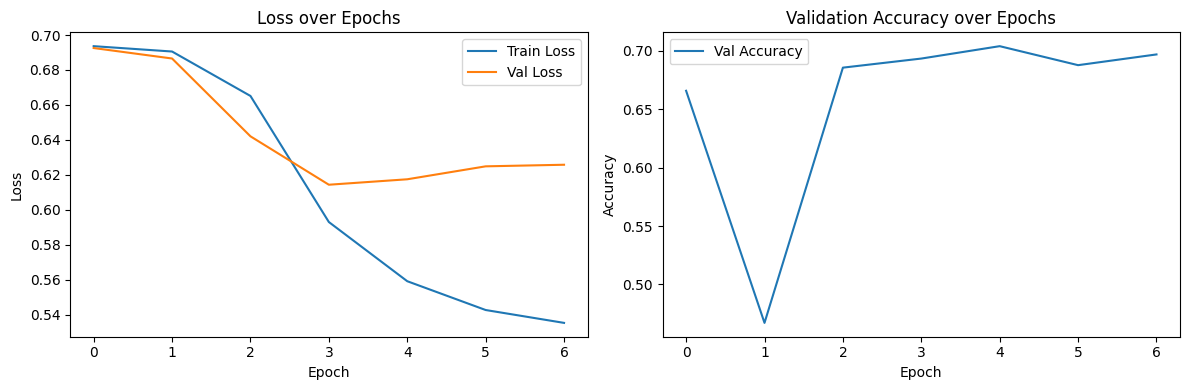

accuracy              : 0.6933
precision             : 0.5391
recall                : 0.5687
f1                    : 0.5535
specificity           : 0.7558
mcc                   : 0.3204
auroc                 : 0.7225
average_precision     : 0.5807
log_loss              : 0.6052
majority_baseline_acc : 0.6657
rrmse                 : 0.7875

NOTE: compare accuracy with 'majority_baseline_acc' - always predicting the bigger class already scores that.

               precision    recall  f1-score   support

Non-offensive       0.78      0.76      0.77       942
    Offensive       0.54      0.57      0.55       473

     accuracy                           0.69      1415
    macro avg       0.66      0.66      0.66      1415
 weighted avg       0.70      0.69      0.70      1415



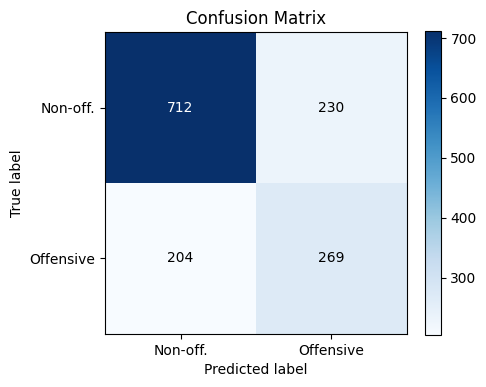

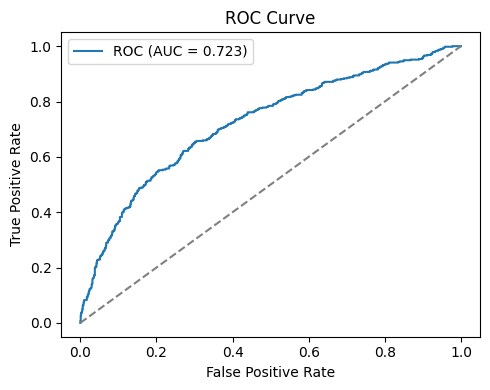

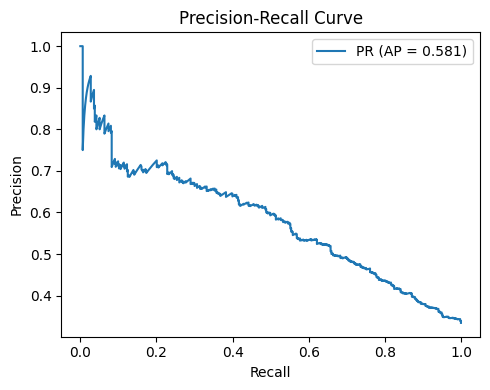

Saved final_metrics.json and the plots to /kaggle/working


In [21]:
val_loss, y_val_final, y_val_pred, y_val_prob = evaluate(model, val_loader, criterion)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss"); plt.plot(history["val_loss"], label="Val Loss")
plt.title("Loss over Epochs"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history["val_acc"], label="Val Accuracy")
plt.title("Validation Accuracy over Epochs"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=120); plt.show()

cm = confusion_matrix(y_val_final, y_val_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
final_metrics = {
    "accuracy": accuracy_score(y_val_final, y_val_pred),
    "precision": precision_score(y_val_final, y_val_pred, zero_division=0),
    "recall": recall_score(y_val_final, y_val_pred, zero_division=0),
    "f1": f1_score(y_val_final, y_val_pred, zero_division=0),
    "specificity": float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0,
    "mcc": float(matthews_corrcoef(y_val_final, y_val_pred)),
    "auroc": float(roc_auc_score(y_val_final, y_val_prob)),
    "average_precision": float(average_precision_score(y_val_final, y_val_prob)),
    "log_loss": float(log_loss(y_val_final, np.clip(y_val_prob, 1e-7, 1 - 1e-7))),
    "majority_baseline_acc": float(max(np.mean(y_val_final == 0), np.mean(y_val_final == 1))),
}
rmse = np.sqrt(np.mean((y_val_final - y_val_prob) ** 2))
final_metrics["rrmse"] = float(rmse / np.sqrt(np.mean(y_val_final ** 2))) if np.mean(y_val_final ** 2) > 0 else float(rmse)

for k, v in final_metrics.items():
    print(f"{k:22s}: {v:.4f}")
print("\nNOTE: compare accuracy with 'majority_baseline_acc' - always predicting the bigger class already scores that.\n")
print(classification_report(y_val_final, y_val_pred, target_names=["Non-offensive", "Offensive"], zero_division=0))

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues"); plt.title("Confusion Matrix"); plt.colorbar()
plt.xticks([0, 1], ["Non-off.", "Offensive"]); plt.yticks([0, 1], ["Non-off.", "Offensive"])
plt.xlabel("Predicted label"); plt.ylabel("True label")
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=120); plt.show()

fpr, tpr, _ = roc_curve(y_val_final, y_val_prob)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc(fpr, tpr):.3f})"); plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "roc_curve.png"), dpi=120); plt.show()

precisions, recalls, _ = precision_recall_curve(y_val_final, y_val_prob)
plt.figure(figsize=(5, 4))
plt.plot(recalls, precisions, label=f"PR (AP = {final_metrics['average_precision']:.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Precision-Recall Curve"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "pr_curve.png"), dpi=120); plt.show()

with open(os.path.join(OUT_DIR, "final_metrics.json"), "w") as f:
    json.dump(final_metrics, f, indent=2)
print("Saved final_metrics.json and the plots to", OUT_DIR)

In [22]:

print("y_val_final:", len(y_val_final))
print("y_val_pred :", len(y_val_pred))
print("y_val_prob :", len(y_val_prob))

print("\nAvailable variables that may contain validation data:")
print([name for name in globals() if "val" in name.lower() and isinstance(globals()[name], pd.DataFrame)])


y_val_final: 1415
y_val_pred : 1415
y_val_prob : 1415

Available variables that may contain validation data:
['val_data']


## 13. Decision-threshold tuning 

In [25]:
idx = np.arange(len(y_val_final))
idx_tune, idx_report = train_test_split(idx, test_size=0.5, random_state=SEED, stratify=y_val_final)

thresholds = np.arange(0.2, 0.81, 0.02)
best_t = max(thresholds, key=lambda t: f1_score(
    y_val_final[idx_tune], (y_val_prob[idx_tune] >= t).astype(int), zero_division=0))

def report_at(t, ids):
    yt, pr = y_val_final[ids], (y_val_prob[ids] >= t).astype(int)
    return {"threshold": round(float(t), 2),
            "accuracy": round(accuracy_score(yt, pr), 4),
            "precision": round(precision_score(yt, pr, zero_division=0), 4),
            "recall": round(recall_score(yt, pr, zero_division=0), 4),
            "f1": round(f1_score(yt, pr, zero_division=0), 4),
            "mcc": round(float(matthews_corrcoef(yt, pr)), 4)}

print("Held-out half, default threshold 0.50:", report_at(0.5, idx_report))
print("Held-out half, tuned threshold       :", report_at(best_t, idx_report))
print("\n(Tuned on the other half. If the numbers barely move, report 0.50 and say so.)")

Held-out half, default threshold 0.50: {'threshold': 0.5, 'accuracy': 0.7034, 'precision': 0.5556, 'recall': 0.5696, 'f1': 0.5625, 'mcc': 0.3383}
Held-out half, tuned threshold       : {'threshold': 0.46, 'accuracy': 0.6893, 'precision': 0.5298, 'recall': 0.6371, 'f1': 0.5785, 'mcc': 0.3393}

(Tuned on the other half. If the numbers barely move, report 0.50 and say so.)


In [25]:

from IPython.display import display
from PIL import Image
import io
import ipywidgets as widgets

upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload a meme"
)

display(upload)


FileUpload(value=(), accept='image/*', description='Upload a meme')

Enter the text written in the meme:  jew mad? get fuhrerious!


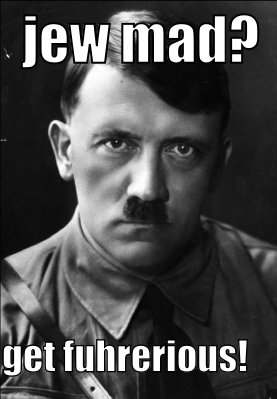

Meme text: jew mad? get fuhrerious!


In [30]:

# Enter the text written in the meme
meme_text = input("Enter the text written in the meme: ")

# Display the uploaded image
if not upload.value:
    print("Upload a meme first, then run this cell again.")
else:
    uploaded_file = upload.value

    # Handle common ipywidgets FileUpload formats
    if isinstance(uploaded_file, dict):
        file_info = next(iter(uploaded_file.values()))
        image_bytes = file_info["content"]
    else:
        file_info = uploaded_file[0]
        image_bytes = file_info["content"]

    new_image = Image.open(io.BytesIO(image_bytes)).convert("RGB")
    display(new_image)
    print("Meme text:", meme_text)


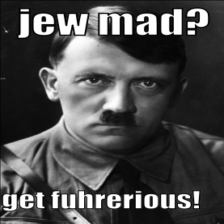


========== MEME PREDICTION ==========
Meme text: jew mad? get fuhrerious!
Predicted class: Offensive
Non-offensive probability: 27.13%
Offensive probability:     72.87%


In [31]:

# ================= PREDICT A NEW MEME =================
import os
import numpy as np
import torch
from PIL import Image
from IPython.display import display

# 1. Prepare the uploaded image using the same preprocessing as training
new_image = new_image.convert("RGB").resize(
    (IMG_SIZE, IMG_SIZE), Image.BILINEAR
)
display(new_image)

image_key = "__uploaded_new_meme__"
IMG_CACHE[image_key] = np.array(new_image, dtype=np.uint8)

# 2. Convert the meme text using the SAME trained TF-IDF and SVD
new_text_sparse = tfidf.transform([str(meme_text)])
new_text_features = svd.transform(new_text_sparse).astype(np.float32)

# 3. Create the dataset in the format expected by your model
new_ds = MemeDataset(
    [image_key],
    new_text_features,
    [0],             # Dummy label; NOT used for prediction
    IMG_CACHE
)
new_loader = make_loader(new_ds, shuffle=False)

# 4. Load the best trained model
model.load_state_dict(torch.load(
    os.path.join(OUT_DIR, "best_model.pt"),
    map_location=DEVICE,
    weights_only=True
))
model.to(DEVICE)
model.eval()

# 5. Predict
with torch.no_grad():
    for images, text_features, _ in new_loader:
        images = images.to(DEVICE)
        text_features = text_features.to(DEVICE)

        with autocast_ctx():
            logits = model(images, text_features)

        probabilities = torch.softmax(logits.float(), dim=1)[0]
        predicted_label = int(torch.argmax(probabilities).item())

# 6. Display the result
class_names = {
    0: "Non-offensive",
    1: "Offensive"
}

print("\n========== MEME PREDICTION ==========")
print("Meme text:", meme_text)
print("Predicted class:", class_names[predicted_label])
print(f"Non-offensive probability: {probabilities[0].item()*100:.2f}%")
print(f"Offensive probability:     {probabilities[1].item()*100:.2f}%")
print("=====================================")
